# S³ semantic-axis smoke test

This exploratory test fits Turftopic S³ to the existing semantic passages using the saved BGE-M3 vectors. Passage embeddings are loaded from disk and passed through `embeddings=`; they are not recomputed. The matching local BGE model is used only for vocabulary-term embeddings.

This fit uses 10 components and seed 42, as a first larger-axis run. Scores are signed ICA coordinates, not calibrated probabilities or BERTopic topics. Review the displayed positive/negative evidence before interpreting an axis. Original BERTopic assignments are not changed.

Run from the repository root with `uv run --group topic-analysis jupyter lab`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 10, 42
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

Project: C:\Users\risto\projects\arvamusfestivali_salvestused
Saved vectors: C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\bubble-maps\segment-embeddings.npy


C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\_snmf.py:20: UserWarning: JAX not found, continuing with NumPy implementation.
  warnings.warn("JAX not found, continuing with NumPy implementation.")


In [2]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

Validated 4,132 passages × 1024 dimensions; float32, finite, L2-normalized.
Model: BAAI/bge-m3 @ 5617a9f61b028005a4858fdac845db406aefb181
Original BERTopic outliers (topic -1): 827


## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [3]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Output()

C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\sklearn\decompositio
n\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum 
number of iterations.
  warnings.warn(

[18:22:51] Decomposition done.                                                                        ]8;id=43960;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=535739;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#156\156]8;;\

[18:22:54] Term extraction done.                                                                      ]8;id=891708;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=435139;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#159\159]8;;\

[18:23:08] Vocabulary encoded.                                                                        ]8;id=387244;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=244106;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#169\169]8;;\

           Model fitting done.                                                                        ]8;id=687803;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=810899;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#189\189]8;;\

S³ fit passed: 4,132 passages, 10 components, seed 42.
Passage vectors came from disk; no passage re-embedding was run.


## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [4]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

S³ passages scored: 4,132; missing passage texts: 0; blank passage texts: 0
Continuous score distribution and exploratory dominant-axis counts (not topic membership)


,component_id,passage_count,score_nan_count,positive_score_count,negative_score_count,mean_score,score_std,min_score,max_score,dominant_axis_passages_exploratory
0,0,4132,0,2087,2045,1.477134e-07,1.0,-3.243202,3.023561,388
1,1,4132,0,1741,2391,1.490982e-07,1.0,-2.542190,4.660161,349
2,2,4132,0,2054,2078,1.772560e-07,1.0,-3.009611,2.770275,393
3,3,4132,0,2092,2040,4.616042e-08,1.0,-3.107951,2.713102,441
4,4,4132,0,2074,2058,-5.169967e-08,1.0,-3.050677,2.866768,459
5,5,4132,0,2066,2066,-8.216555e-08,1.0,-2.842831,2.692226,434
6,6,4132,0,2046,2086,2.584984e-07,1.0,-3.269853,2.897101,449
7,7,4132,0,2086,2046,-3.840547e-07,1.0,-3.033273,2.765562,407
8,8,4132,0,2028,2104,9.601368e-08,1.0,-2.559021,2.852794,386
9,9,4132,0,2114,2018,-4.652971e-07,1.0,-3.334119,3.220247,426


Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.


,component_id,positive_end_terms,negative_end_terms,reviewed_bipolar_label,review_notes
0,0,"tööle, tööd, läks, töö, korraks, jooksul, mine...","riigi, arutelu, ees, parem, protsenti, riik, s...",,
1,1,"kelle, arutelu, kes, räägime, olin, arvan, ole...","põhimõtteliselt, no, vähem, tähendab, lihtne, ...",,
2,2,"koolis, ai, õpetaja, it, kooli, midagi, räägi,...","riik, ees, arust, oska, euroopa, hea, hoida, r...",,
3,3,"arutelu, mõtlema, raha, nõus, vähem, öelda, mõ...","teen, selles, noor, ees, eriti, kodus, it, koo...",,
4,4,"maailma, inimesed, inimeste, rääkida, sõna, ol...","raha, tööle, it, ega, ai, tööd, käib, kokku, s...",,
5,5,"hea, mõju, mind, inimese, mõtlema, tea, tee, a...","riigi, riik, euroopa, eest, eesti, kuhu, vot, ...",,
6,6,"õpetaja, koolis, eesmärk, ise, euroopa, maailm...","väike, lahti, kodus, kinni, palun, juures, pea...",,
7,7,"õpetaja, tööle, koolis, minema, töö, lapsed, h...","ai, it, maailma, vot, noh, arust, maailmas, et...",,
8,8,"koolis, kooli, teen, õpetaja, väike, mitu, tee...","inimese, inimeste, inimene, inimest, euroopa, ...",,
9,9,"ai, it, arvan, riik, kodus, kes, töö, sisse, s...","mingisugune, mingisuguse, erinevaid, mõned, er...",,


S3_COMPONENT_STATS_OK passages=4,132; components=10; missing_scores=0


## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

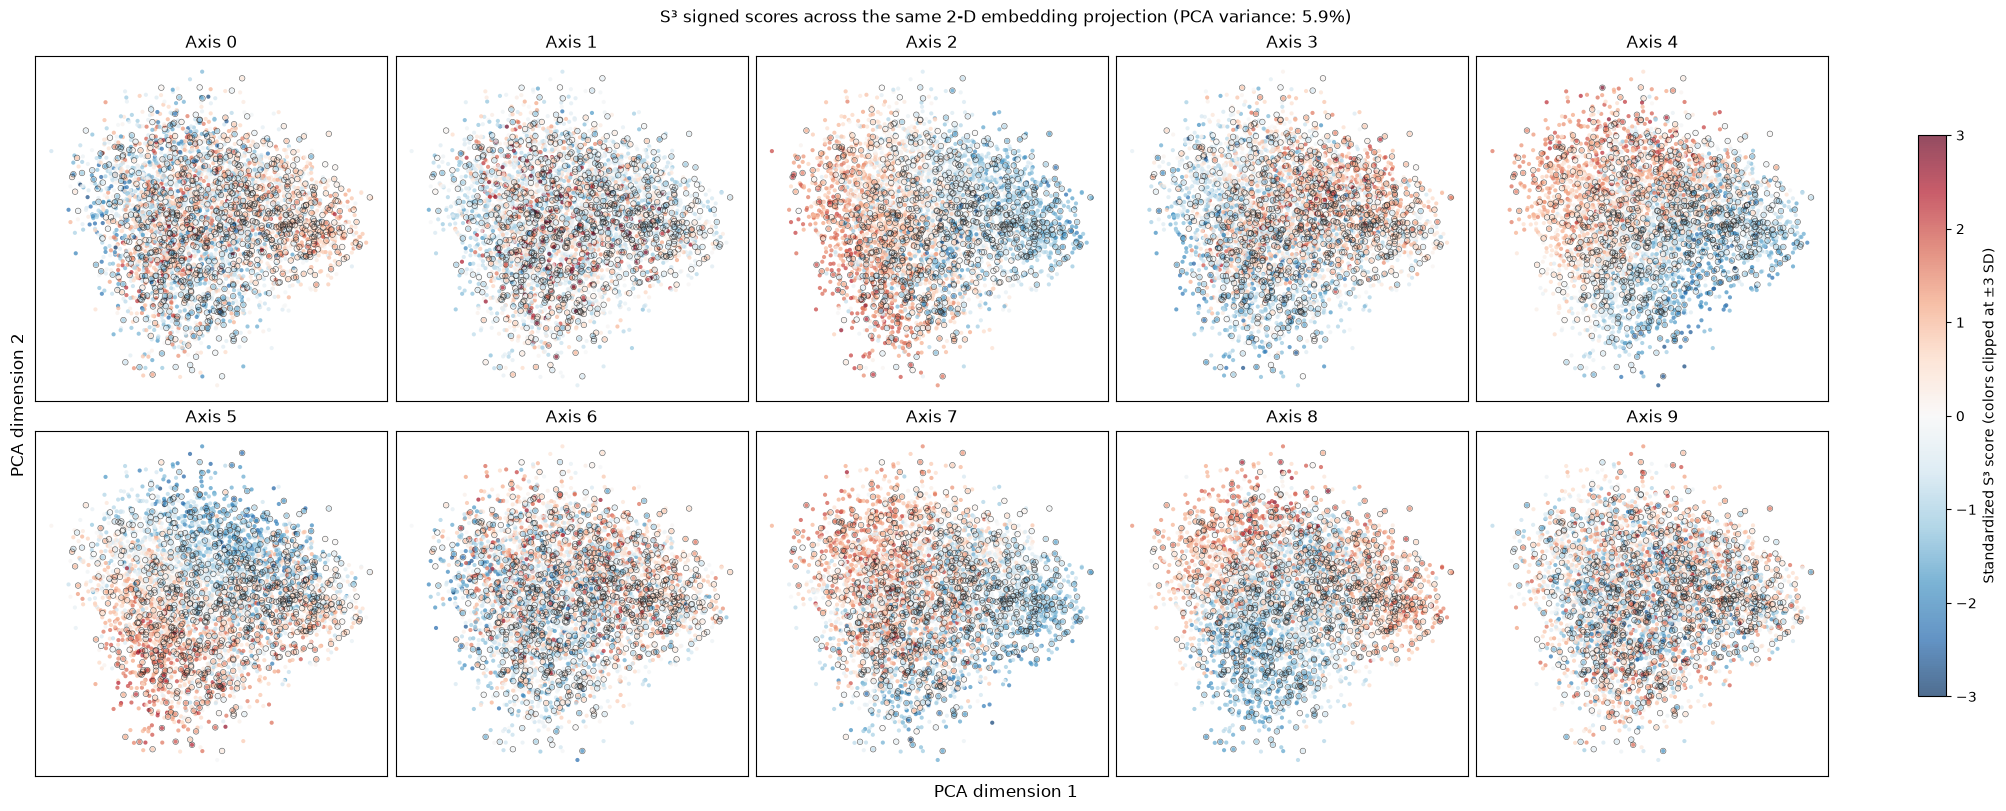

2-D projection uses the saved 1024-D vectors for 4,132 passages; BERTopic outliers outlined: 827.
Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.


,axis,positive terms,positive passage,negative terms,negative passage
0,0,"tööle, tööd, läks, töö, korraks, jooksul, mine...",2247188684 | Kas kiirustades elad kauem? | 435...,"riigi, arutelu, ees, parem, protsenti, riik, s...",2293106228 | Kelle mure on laste suutervis_ | ...
1,1,"kelle, arutelu, kes, räägime, olin, arvan, ole...",2254333412 | Millist väliruumi ootame oma linn...,"põhimõtteliselt, no, vähem, tähendab, lihtne, ...","2395991463 | Mees, kus su lapsed on_ | 4516.52..."
2,2,"koolis, ai, õpetaja, it, kooli, midagi, räägi,...",2395991469 | Kes võidab AI-ajastul_ | 394.72–9...,"riik, ees, arust, oska, euroopa, hea, hoida, r...",2397177255 | Vabakutseliste loovisikute toimet...
3,3,"arutelu, mõtlema, raha, nõus, vähem, öelda, mõ...",2247188705 | Kas töötaja on alati nõrgem osapo...,"teen, selles, noor, ees, eriti, kodus, it, koolis",2293106231 | Haigekassa nõukogu kriisikoosolek...
4,4,"maailma, inimesed, inimeste, rääkida, sõna, ol...",2250797879 | Looduskaitse ja riigikaitse – tei...,"raha, tööle, it, ega, ai, tööd, käib, kokku",2400207741 | Kuidas rahastada terviseidusid ni...
5,5,"hea, mõju, mind, inimese, mõtlema, tea, tee, aeg",2302899434 | Infraheli ja tuulepargid – müüt v...,"riigi, riik, euroopa, eest, eesti, kuhu, vot, ...",2314163810 | Maailm täna - vaade julgeolekuolu...
6,6,"õpetaja, koolis, eesmärk, ise, euroopa, maailm...",2393585469 | Mida Eesti tegelikult kõrgharidus...,"väike, lahti, kodus, kinni, palun, juures, pea...",2293106228 | Kelle mure on laste suutervis_ | ...
7,7,"õpetaja, tööle, koolis, minema, töö, lapsed, h...",2293106216 | Kuidas KOOSTÖÖS kasutada ära Eest...,"ai, it, maailma, vot, noh, arust, maailmas, et",2271676355 | Valel on ohtlikud jalad ehk kuida...
8,8,"koolis, kooli, teen, õpetaja, väike, mitu, tee...",2310594917 | Milline koolivõrk suudab kasvatad...,"inimese, inimeste, inimene, inimest, euroopa, ...",2247188693 | Töökius otse laval | 3616.48–3881...
9,9,"ai, it, arvan, riik, kodus, kes, töö, sisse",2247188684 | Kas kiirustades elad kauem? | 450...,"mingisugune, mingisuguse, erinevaid, mõned, er...",2293106222 | Süstime rahva saledaks_ | 146.36–...


In [5]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True, constrained_layout=True)
for component_id, ax in enumerate(axes.flat):
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

## Existing BERTopic groups across S³ axes

Each passage keeps its original BERTopic `topic_id` and membership strength. The heatmap summarizes mean standardized S³ scores for every topic × axis. Below, boxplot grids place original BERTopic topics in rows and S³ axes in columns; topic `-1` is retained. These are group associations, not recalculated BERTopic probabilities or a correlation with numeric topic IDs.

Raw per-passage S³ scores and topic-by-axis quantiles are saved as separate Parquet outputs; original assignments are not changed.

In [6]:
from pathlib import Path
import plotly.graph_objects as go
import sys
sys.path.insert(0, str(project_root))
from scripts.s3_topic_axis import summarize_topic_axis_scores

topic_axis_summary = summarize_topic_axis_scores(passages, score_frame)
assert topic_axis_summary.axis_id.nunique() == N_COMPONENTS
assert topic_axis_summary.passage_count.sum() == len(passages) * N_COMPONENTS
assert (topic_axis_summary.topic_id == -1).any(), 'BERTopic outlier group -1 should be retained'
assert np.array_equal(scored_passages.topic_id.to_numpy(), passages.topic_id.to_numpy())
if 'membership_strength' in passages:
    assert np.allclose(scored_passages.membership_strength.to_numpy(dtype=float), passages.membership_strength.to_numpy(dtype=float), equal_nan=True)

score_output_dir = results / 'jev-semantic-all' / 's3-topic-axis-distributions'
score_output_dir.mkdir(parents=True, exist_ok=True)
run_tag = f'k{N_COMPONENTS}-seed{RANDOM_STATE}'
passage_score_path = score_output_dir / f'passage-scores-{run_tag}.parquet'
topic_axis_summary_path = score_output_dir / f'topic-axis-summary-{run_tag}.parquet'
export_columns = [column for column in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if column in scored_passages] + score_columns
scored_passages[export_columns].to_parquet(passage_score_path, index=False)
topic_axis_summary.to_parquet(topic_axis_summary_path, index=False)

topic_order = sorted(topic_axis_summary.topic_id.unique().tolist())
topic_means = topic_axis_summary.pivot(index='topic_id', columns='axis_id', values='mean_score').reindex(index=topic_order, columns=range(N_COMPONENTS))
topic_counts = topic_axis_summary.pivot(index='topic_id', columns='axis_id', values='passage_count').reindex(index=topic_order, columns=range(N_COMPONENTS))
axis_means = score_frame.mean().to_numpy()
axis_stds = score_frame.std(ddof=0).replace(0, 1).to_numpy()
topic_mean_z = (topic_means.to_numpy() - axis_means) / axis_stds
heat_custom = np.stack([topic_counts.to_numpy(), topic_means.to_numpy()], axis=-1)
heat = go.Figure(go.Heatmap(z=topic_mean_z, x=[f'Axis {i}' for i in range(N_COMPONENTS)], y=[str(topic) for topic in topic_order], customdata=heat_custom, colorscale='RdBu_r', zmid=0, zmin=-2, zmax=2, colorbar={'title': 'Mean S³ z-score'}, hovertemplate='BERTopic topic %{y}<br>%{x}<br>mean score z=%{z:.2f}<br>passages=%{customdata[0]:.0f}<extra></extra>'))
heat.update_layout(title=f'Mean S³ score by original BERTopic topic (k={N_COMPONENTS})', xaxis_title='S³ axis', yaxis_title='Original BERTopic topic ID', height=max(700, min(1400, 9 * len(topic_order))), margin={'l': 90, 'r': 30, 't': 70, 'b': 70})
heat.show()

from plotly.subplots import make_subplots

# Keep every topic and axis, but split the tall matrix into readable pages.
topics_per_page = 20
for page_start in range(0, len(topic_order), topics_per_page):
    page_topics = topic_order[page_start:page_start + topics_per_page]
    distribution = make_subplots(
        rows=len(page_topics), cols=N_COMPONENTS,
        shared_xaxes=False, shared_yaxes=False,
        horizontal_spacing=0.025, vertical_spacing=min(0.02, 0.3 / max(1, len(page_topics))),
        subplot_titles=[f'S³ axis {axis_id}' for _topic in page_topics for axis_id in range(N_COMPONENTS)],
    )
    for row, topic_id in enumerate(page_topics, start=1):
        topic_mask = scored_passages.topic_id.to_numpy() == topic_id
        for col, score_column in enumerate(score_columns, start=1):
            distribution.add_trace(
                go.Box(x=score_z.loc[topic_mask, score_column], y=[str(topic_id)] * int(topic_mask.sum()),
                       orientation='h', boxpoints=False, showlegend=False,
                       hovertemplate=f'Topic {topic_id}<br>standardized S³ score=%{{x:.2f}}<extra></extra>'),
                row=row, col=col,
            )
        distribution.update_yaxes(title_text=f'Topic {topic_id}', showticklabels=False, row=row, col=1)
    distribution.update_xaxes(title_text='Standardized S³ score (not a probability)')
    distribution.update_layout(
        title=f'S³ score distributions by original BERTopic topic × axis (topics {page_topics[0]}–{page_topics[-1]})',
        height=max(900, 105 * len(page_topics)), showlegend=False,
        margin={'l': 100, 'r': 25, 't': 90, 'b': 65},
    )
    distribution.show()

print(f'Passage scores: {len(scored_passages):,} rows × {N_COMPONENTS} axes; BERTopic outliers retained: {(passages.topic_id == -1).sum():,}.')
print(f'Wrote {passage_score_path} and {topic_axis_summary_path}')
display(topic_axis_summary.sort_values('passage_count', ascending=False).head(12).reset_index(drop=True))

Passage scores: 4,132 rows × 10 axes; BERTopic outliers retained: 827.
Wrote C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\s3-topic-axis-distributions\passage-scores-k10-seed42.parquet and C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\s3-topic-axis-distributions\topic-axis-summary-k10-seed42.parquet


,topic_id,axis_id,passage_count,mean_score,std_score,median_score,q10_score,q25_score,q75_score,q90_score
0,-1,9,827,-0.090952,1.015217,-0.087914,-1.477774,-0.773339,0.698905,1.202625
1,-1,8,827,0.094199,1.026242,0.158186,-1.271375,-0.752995,0.902002,1.438551
2,-1,6,827,0.108458,0.976125,0.082611,-1.166232,-0.548425,0.764461,1.362578
3,-1,7,827,-0.182930,0.987230,-0.256807,-1.390546,-0.942867,0.502097,1.177055
4,-1,1,827,0.059992,1.093279,-0.119124,-1.049910,-0.693456,0.455515,1.382480
5,-1,0,827,-0.018176,0.917143,0.051160,-1.303259,-0.675919,0.666985,1.081331
6,-1,4,827,-0.031015,0.959827,-0.016461,-1.315414,-0.745067,0.698937,1.214641
7,-1,5,827,0.147470,1.019942,0.172563,-1.316601,-0.545965,0.901609,1.441846
8,-1,2,827,-0.130715,0.982126,-0.193382,-1.336877,-0.867976,0.555718,1.267852
9,-1,3,827,0.010811,0.969317,0.044432,-1.264738,-0.643164,0.728325,1.247434


In [7]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

Component 0: highest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2247188684:000000435160-000000565960,2247188684,Kas kiirustades elad kauem?,435.16,565.96,"üheksa isegi. Ei lähe paremuse poole, veel ei ...",1,0.179744,3.023561
1,2395991466:000004334400-000004493480,2395991466,Miks noored mehed surevad_,4334.40,4493.48,"viidi läbi suuri arenguid. Ja üks, üks asi, mi...",1,0.403983,2.965935
2,2400207765:000002441200-000002768280,2400207765,Üksilduse rohi_ kes vastutab üksilduse eest_,2441.20,2768.28,"jetaja ja mu naine pärast küsis, et et noh, ka...",14,0.076099,2.875025


Component 0: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2293106228:000004826440-000005068173,2293106228,Kelle mure on laste suutervis_,4826.44,5068.173,"Jätkan natuke sellesama teemaga, sellepärast e...",30,0.142749,-3.243202
1,2289585017:000000011280-000000110880,2289585017,Vanematega kohtupinki – digilaste tulevik_,11.28,110.880,"Tere õhtust kõigile, kes te olete tulnud kuula...",41,0.359083,-3.151599
2,2396670915:000000380360-000000544000,2396670915,Pedofiilia uus nägu_ kuidas avatus loob uusi r...,380.36,544.000,häiritud seksuaalsusega. Et enamus neist ei ol...,95,1.000000,-3.054636


Component 1: highest-scoring passages


...

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_9
0,2247188684:000004506880-000005090760,2247188684,Kas kiirustades elad kauem?,4506.88,5090.76,Ma väga tänan. Tuleks veel ja edu siis metsate...,1,0.805689,3.220247
1,2396692746:000003531480-000004088560,2396692746,Kuidas hoida kokkuleppeid ruumis_,3531.48,4088.56,"ssurssi väheks ja teine asi muidugi on see, et...",94,1.000000,2.617100
2,2302899440:000000011800-000000463200,2302899440,Rohetehnoloogiad – puhta tööstuse ja julgeolek...,11.80,463.20,"Aga kena, kell on saanud kaksteist ja natukene...",5,0.490508,2.581893


Component 9: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_9
0,2293106222:000000146360-000000275800,2293106222,Süstime rahva saledaks_,146.36,275.80,"stiile ehk harjumused, mängib toidu kvaliteet ...",47,1.000000,-3.334119
1,2396670936:000001279560-000001412440,2396670936,"Kas Eesti on valmis järgmiseks kriisiks, mis e...",1279.56,1412.44,ng presented. So what do? We will turn them to...,96,0.062367,-3.109052
2,2397264576:000003085440-000003192480,2397264576,Kas linnud ja loomad keedavad meile uut superh...,3085.44,3192.48,"Et nähti, et taus on majanduslikult oluliselt,...",131,1.000000,-3.095029


Outliers shown for additional evidence review: 827 total; first 12 by absolute component-0 score.


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0,s3_component_1,s3_component_2,s3_component_3,s3_component_4,s3_component_5,s3_component_6,s3_component_7,s3_component_8,s3_component_9
0,2293106219:000001661280-000002057120,2293106219,Ravivalikute loterii - miks mõni haigus saab k...,1661.28,2057.12,"isukohti ju meedias, et võib-olla me peaksime ...",-1,NaN,-2.911903,-0.743084,-2.361326,-0.218358,-1.711581,-0.296738,-0.353368,1.993235,-0.557137,-0.389833
1,2267420993:000001581320-000001721080,2267420993,"Mõõdame eurodes, mitte tihumeetrites",1581.32,1721.08,"Fredi, sina küpsetad puitu kaugetele eksootili...",-1,NaN,2.653742,-0.428019,-0.390536,-0.200307,-0.201301,-0.677338,-0.852065,-0.902019,0.068878,-0.689699
2,2271676355:000001926800-000002025960,2271676355,Valel on ohtlikud jalad ehk kuidas väärinfo oh...,1926.80,2025.96,", siis kellele loota sotsiaalmeedias. Et noh, ...",-1,NaN,-2.486183,-0.256415,1.206505,0.629310,-0.564919,-0.959681,-0.357475,-2.520856,-1.611877,-1.736153
3,2400207750:000002802840-000002963880,2400207750,Eesti terviseandmed_ kristallkuul või kompass_,2802.84,2963.88,see on nagu neid andmeid küsima hakkad. No sii...,-1,NaN,-2.380099,-0.192451,-1.736242,0.330640,-0.453572,2.314218,0.860277,0.359218,-1.892757,-0.358045
4,2400207762:000000011200-000000214880,2400207762,Kelle vastutus on ennetus tervishoius_,11.20,214.88,"Ja tere, head inimesed, kes te olete kogunenud...",-1,NaN,-2.323914,3.730603,-1.411623,0.221360,0.525443,1.010001,-0.024987,0.794449,-1.017891,0.724979
5,2400164907:000004579720-000004772800,2400164907,Iga lapse tulevik on Eesti arenguküsimus,4579.72,4772.80,"mist lasteaedades, siis lihtsalt fakti mõttes,...",-1,NaN,-2.269814,-1.233892,0.111957,1.506833,0.577378,-1.511690,-1.353149,0.829120,1.012767,0.056915
6,2280202457:000001201520-000001294480,2280202457,Naised ettevõtluses sotsiodraama_ Kuidas tappa...,1201.52,1294.48,"pluss aastat töötasin ma siis ka noh, Eesti mõ...",-1,NaN,2.214001,0.097960,0.090676,-0.232916,-0.744979,-0.510601,0.307218,0.396421,-0.211841,-1.833562
7,2247188699:000001827280-000002278640,2247188699,Õpiamps kui osa tööst,1827.28,2278.64,"Mina ütlesin, et mida mina näen, et mida on Ee...",-1,NaN,2.182082,-0.244520,0.794950,-0.361927,-0.979897,0.399415,1.236207,1.073468,-0.247962,1.262286
8,2302899434:000003950200-000004046360,2302899434,Infraheli ja tuulepargid – müüt või tegelik mõ...,3950.20,4046.36,on saanud järglased. Ehk siis tegelikult teda ...,-1,NaN,-2.181372,-0.706359,-1.457034,0.714736,0.492455,1.060801,-0.706555,-0.375660,-0.219569,-0.269160
9,2289585017:000004170120-000004300360,2289585017,Vanematega kohtupinki – digilaste tulevik_,4170.12,4300.36,"tõesti, et see tekitab lastele sellist kuuluvu...",-1,NaN,-2.143816,-1.526335,2.053093,-0.161826,1.827090,-0.721320,-0.622850,-0.714497,0.508681,-0.660453
